# Testes de Granger por UF e tipologia

Este caderno avalia se as defasagens dos registros de uma tipologia acrescentam informação sobre a inadimplência àquela contida no histórico da própria taxa.

As regressões usam Δlog(I) e Δlog(1+D), intercepto e onze indicadores mensais. A ordem é selecionada pelo BIC entre um e seis meses, sobre amostra comum. Benjamini–Hochberg é aplicado às famílias de 16 tipologias de cada UF e recorte. O teste examina precedência preditiva.

As [especificações](../docs/metodologia_e_sensibilidades.md) e a [síntese dos resultados](../docs/resultados.md) contextualizam tabelas e diagnósticos.

In [1]:
from pathlib import Path
import pandas as pd
ROOT=Path.cwd()
if not (ROOT/'outputs').exists(): ROOT=ROOT.parent
B=ROOT/'outputs/tables/modalidades_excluidas_20261104'
import json
manifest=json.loads((B/'manifesto.json').read_text(encoding='utf-8'))
print('Base PF com três exclusões:', manifest['base_sha256'])
print('Período:', manifest['periodo'], 'Observações:', manifest['linhas'])


Base PF com três exclusões: d795e0ed176cc4628e1b02a81bc32ecab449f24aefc3e9be91d291479f46c043
Período: ['2013-01', '2024-12'] Observações: 3888


In [2]:
g=pd.read_csv(B/'granger/granger_aplicacoes.csv'); assert len(g)==864; print(g.groupby('periodo').agg(planejados=('uf','size'),estimaveis=('status',lambda x:x.eq('estimado').sum()),nominais=('rejeicao_nominal','sum'),BH=('rejeicao_bh','sum')).to_string())

         planejados  estimaveis  nominais  BH
periodo                                      
Pré             432         292        33   9
Total           432         335        23   7


Defasagens escolhidas pelo BIC:
p_lags
1    299
2    221
3     94
4      7
5      6


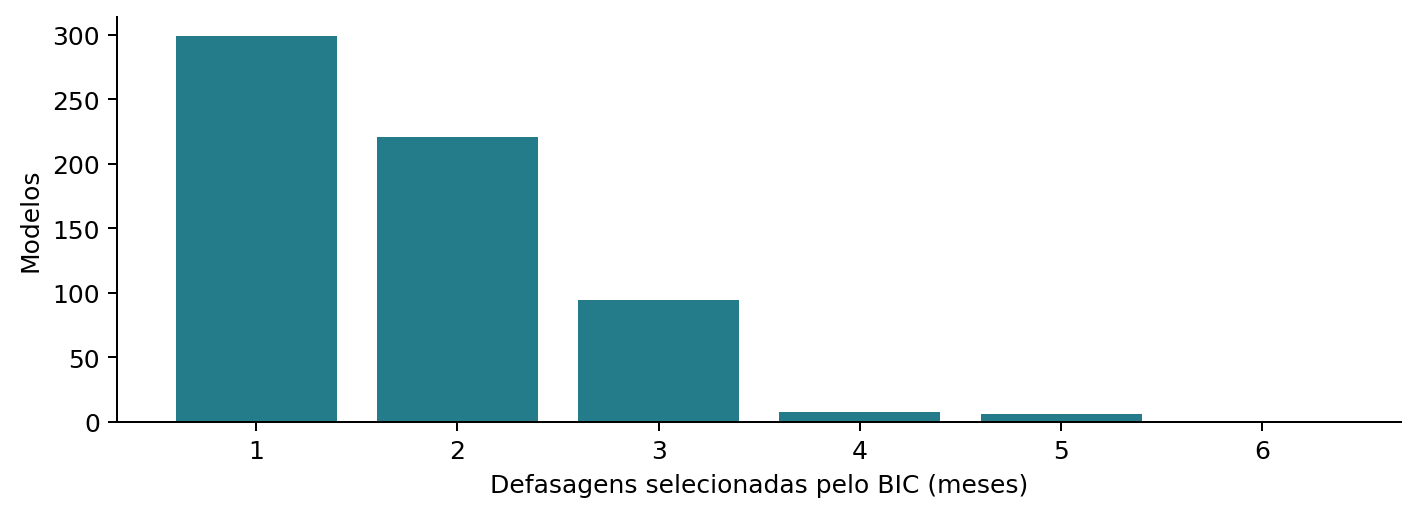

In [3]:
print('Defasagens escolhidas pelo BIC:'); print(g.p_lags.dropna().astype(int).value_counts().sort_index().to_string())
from IPython.display import display, Image
display(Image(filename=str(ROOT/'outputs/figures/modalidades_excluidas_20261104/granger_defasagens.png')))

In [4]:
z=g[g.rejeicao_bh]; print(z[['uf','periodo','tipologia','p_lags','p','q_bh','ljungbox_p']].to_string(index=False)); print('Rejeições BH com autocorrelação:',int(z.ljungbox_p.lt(.05).sum()))

uf periodo                          tipologia  p_lags            p         q_bh  ljungbox_p
AL     Pré                   tipo_alagamentos     1.0 7.358821e-03 3.463151e-02    0.923490
AL     Pré               tipo_chuvas_intensas     1.0 8.657878e-03 3.463151e-02    0.941237
AL     Pré                    tipo_enxurradas     1.0 7.358821e-03 3.463151e-02    0.923490
AL     Pré                    tipo_inundacoes     1.0 7.358821e-03 3.463151e-02    0.923490
PA     Pré                   tipo_alagamentos     2.0 2.728453e-03 4.365525e-02    0.200354
PI     Pré                        tipo_outros     4.0 2.246352e-05 3.594163e-04    0.124523
RN     Pré               tipo_chuvas_intensas     3.0 1.532269e-03 2.451630e-02    0.034304
RR     Pré                   tipo_alagamentos     5.0 3.292039e-09 2.633631e-08    0.021803
RR     Pré               tipo_chuvas_intensas     5.0 4.595875e-11 7.353401e-10    0.179155
GO   Total tipo_onda_de_calor_e_baixa_umidade     5.0 3.373037e-05 5.396859e-04 

## Verificação independente

Os testes F foram recalculados com OLS/f_test e o BH foi refeito por ordenação dos valores-p.

In [5]:
v=pd.read_csv(B/'granger/validacao_independente.csv'); assert len(v)==g.status.eq('estimado').sum(); print('Modelos conferidos:',len(v)); print('Maior diferença no p-valor:',v.erro_p.max())

Modelos conferidos: 627
Maior diferença no p-valor: 4.468536651813793e-12


A evidência é localizada e exploratória. O ajuste BH local não controla toda a família de 864 aplicações, e não incorpora a seleção de p pelo BIC. Os casos com Ljung–Box significativo exigem cautela adicional.